# 01 SDXL 逐格生圖：方案 A（Prompt only baseline）

讀取 `data/storyboards/` 的 5 份凍結分鏡（共 30 格），用 SDXL 逐格生圖。這是一致性實驗的對照組，也用來驗證整條生圖流程。

**執行前**：「執行階段 → 變更執行階段類型」選 **T4 GPU**。

- 生圖參數固定在 `comic_agent.render.GenConfig`（SDXL base 1.0、fp16、DPM++ 2M Karras、30 步、CFG 6.5、1024×1024）
- seed = 故事編號 × 100 + 格數，四種方案共用
- 每張圖旁邊存一份 `.json`，記錄 prompt、seed、參數、耗時、git commit
- 結果存到 Google Drive，**斷線後重跑會略過已完成的格**

In [12]:
# ==== 設定 ====
REPO_URL = "https://github.com/77JoyWang77/1151-AI-Final.git"
REPO_DIR = "/content/1151-AI-Final"
DRIVE_ROOT = "/content/drive/MyDrive/1151-AI-Final"  # 生成結果存這裡
SCHEME = "A"               # 方案 A：prompt only
STORIES = [1]  # 先試跑可改成 [1]
CPU_OFFLOAD = False        # 若出現 CUDA out of memory 改成 True（較慢）

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 取得程式碼

repo 目前是 public，不用設定。若改成 **private**：左側欄「鑰匙」圖示（Secrets）新增 `GH_TOKEN`，值為 GitHub personal access token（只需 repo 讀取權限），並開啟「Notebook access」。

若重啟過執行階段（`/content` 會被清空），要從第一格重新執行。

In [13]:
import base64
import os
import subprocess


def clone(*git_opts):
    return subprocess.run(["git", *git_opts, "clone", "-q", REPO_URL, REPO_DIR], capture_output=True, text=True)


if os.path.isdir(f"{REPO_DIR}/.git"):
    !git -C {REPO_DIR} pull -q --ff-only
else:
    !rm -rf {REPO_DIR}  # 清掉上次 clone 失敗留下的殘骸
    result = clone()  # public repo 不需要 token
    if result.returncode != 0:
        try:
            from google.colab import userdata
            token = (userdata.get("GH_TOKEN") or "").strip()
        except Exception:
            token = ""
        # 不印出 token 內容；檢查前綴，避免誤填成 OpenAI key 等其他密鑰
        if not token.startswith(("ghp_", "github_pat_")):
            raise RuntimeError("clone 失敗，且 Secrets 沒有有效的 GH_TOKEN（GitHub token 以 ghp_ 或 github_pat_ 開頭）\n"
                               + result.stderr)
        # token 放在 HTTP header 而不是網址，git 的錯誤訊息不會把它印出來
        auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
        result = clone("-c", f"http.extraHeader=Authorization: Basic {auth}")
        if result.returncode != 0:
            raise RuntimeError("用 GH_TOKEN clone 仍失敗：\n" + result.stderr)
assert os.path.isdir(f"{REPO_DIR}/src/comic_agent"), "clone 失敗：src/comic_agent 不存在"
!git -C {REPO_DIR} log --oneline -1

4fc24b7 (HEAD -> main, origin/main, origin/HEAD) Harden notebook clone and import cells


In [14]:
!pip install -q diffusers transformers accelerate python-dotenv

In [15]:
import importlib
import json
import subprocess
import sys
import time

if f"{REPO_DIR}/src" not in sys.path:
    sys.path.insert(0, f"{REPO_DIR}/src")
importlib.invalidate_caches()  # 同一個 kernel 若在 clone 前 import 失敗過，Python 會記住「路徑不存在」
from comic_agent import render
from comic_agent.storyboard import estimate_clip_tokens

CONFIG = render.GenConfig()
OUT_ROOT = f"{DRIVE_ROOT}/outputs/render"
GIT_COMMIT = subprocess.check_output(["git", "-C", REPO_DIR, "rev-parse", "--short", "HEAD"], text=True).strip()

boards = render.load_frozen_storyboards(f"{REPO_DIR}/data/storyboards")
jobs = [j for j in render.iter_jobs(boards, SCHEME) if j["story_no"] in STORIES]
print(CONFIG)
print(f"{len(jobs)} 格，commit {GIT_COMMIT}，輸出到 {OUT_ROOT}/{SCHEME}")

GenConfig(model_id='stabilityai/stable-diffusion-xl-base-1.0', vae_id='madebyollin/sdxl-vae-fp16-fix', scheduler='DPM++ 2M Karras', steps=30, cfg=6.5, width=1024, height=1024)
6 格，commit 4fc24b7，輸出到 /content/drive/MyDrive/1151-AI-Final/outputs/render/A


### 載入 SDXL

第一次執行會下載約 7 GB 權重，需要幾分鐘。VAE 換成 `sdxl-vae-fp16-fix`，原版 VAE 在 fp16 下會溢位產生黑圖。

In [16]:
import torch
from diffusers import AutoencoderKL, DPMSolverMultistepScheduler, StableDiffusionXLPipeline

vae = AutoencoderKL.from_pretrained(CONFIG.vae_id, torch_dtype=torch.float16)
pipe = StableDiffusionXLPipeline.from_pretrained(
    CONFIG.model_id, vae=vae, torch_dtype=torch.float16, variant="fp16", use_safetensors=True,
)
# DPM++ 2M Karras
pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe.scheduler.config, algorithm_type="dpmsolver++", solver_order=2, use_karras_sigmas=True,
)
if CPU_OFFLOAD:
    pipe.enable_model_cpu_offload()
else:
    pipe.to("cuda")
pipe.set_progress_bar_config(disable=True)
print(torch.cuda.get_device_name(0), f"{torch.cuda.memory_allocated() / 2**30:.1f} GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


...

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Tesla T4 6.6 GB


### 用真正的 CLIP tokenizer 檢查 prompt 長度

本機只能用 `estimate_clip_tokens()` 粗估。CLIP 上限 77 tokens（含開頭與結尾符號），超過的部分會被截掉。這格同時校正粗估值：若實際值普遍比粗估多，要調低 `MAX_CLIP_TOKENS`。

In [17]:
rows = []
for j in jobs:
    actual = max(len(pipe.tokenizer(j["prompt"]).input_ids), len(pipe.tokenizer_2(j["prompt"]).input_ids))
    rows.append((j["story_no"], j["panel_index"], estimate_clip_tokens(j["prompt"]), actual))

over = [r for r in rows if r[3] > 77]
ratio = sum(r[3] / r[2] for r in rows) / len(rows)
print(f"實際 tokens：最長 {max(r[3] for r in rows)}，超過 77 的格數 {len(over)} / {len(rows)}")
print(f"實際 / 粗估 平均比例 {ratio:.2f}")
for s, p, est, act in over:
    print(f"  story {s} panel {p}: 粗估 {est}，實際 {act}（尾端會被截斷）")
neg = len(pipe.tokenizer(jobs[0]["negative_prompt"]).input_ids)
print(f"negative prompt：{neg} tokens")

實際 tokens：最長 49，超過 77 的格數 0 / 6
實際 / 粗估 平均比例 1.08
negative prompt：26 tokens


In [18]:
from PIL import Image


def generate(job, out_root=OUT_ROOT, skip_existing=True):
    """生成一格並存圖與紀錄；已存在就略過（斷線續跑）。"""
    png, js = render.panel_paths(out_root, job)
    if skip_existing and png.exists() and js.exists():
        return png, False
    generator = torch.Generator("cpu").manual_seed(job["seed"])  # CPU generator：跨機器較可重現
    t0 = time.time()
    image = pipe(
        prompt=job["prompt"],
        negative_prompt=job["negative_prompt"],
        num_inference_steps=CONFIG.steps,
        guidance_scale=CONFIG.cfg,
        width=CONFIG.width,
        height=CONFIG.height,
        generator=generator,
    ).images[0]
    seconds = round(time.time() - t0, 1)
    png.parent.mkdir(parents=True, exist_ok=True)
    image.save(png)
    render.write_record(js, job, CONFIG, seconds=seconds, git_commit=GIT_COMMIT,
                        gpu=torch.cuda.get_device_name(0))
    return png, True

### 試跑一格並檢查可重現性

同一個 seed 再生一次，比較兩張圖的像素差。GPU 運算有微小的非確定性，平均差值接近 0 即可視為可重現。

同 seed 兩次生成的平均像素差：0.00（0–255）


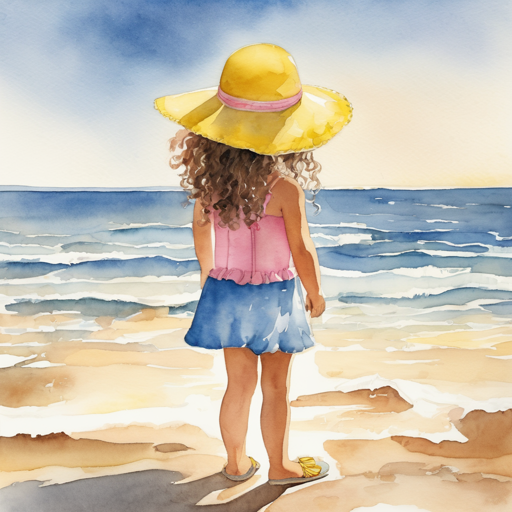

In [19]:
import numpy as np

png, _ = generate(jobs[0])
again, _ = generate(jobs[0], out_root="/content/repro_check", skip_existing=False)
diff = np.abs(np.asarray(Image.open(png), dtype=float) - np.asarray(Image.open(again), dtype=float)).mean()
print(f"同 seed 兩次生成的平均像素差：{diff:.2f}（0–255）")
display(Image.open(png).resize((512, 512)))

### 批次生成

每格約 30–40 秒（T4），30 格約 20 分鐘。斷線後重新執行上面各格與這一格即可續跑。

In [ ]:
for k, job in enumerate(jobs, 1):
    png, new = generate(job)
    status = "生成" if new else "已存在，略過"
    print(f"[{k}/{len(jobs)}] story {job['story_no']} panel {job['panel_index']}：{status}")

[1/6] story 1 panel 1：已存在，略過
[2/6] story 1 panel 2：生成
[3/6] story 1 panel 3：生成
[4/6] story 1 panel 4：生成


### 每篇故事的總覽圖與耗時

總覽圖存成 `<scheme>/story_N/contact.png`。方案 A 沒有任何一致性機制，預期主角在各格的長相會有明顯差異；這正是後續方案 B–D 要改善的地方。

In [ ]:
from pathlib import Path

THUMB = 384
for story_no in STORIES:
    story_dir = Path(OUT_ROOT) / SCHEME / f"story_{story_no}"
    pngs = sorted(story_dir.glob("panel_*.png"))
    if not pngs:
        continue
    sheet = Image.new("RGB", (THUMB * 3, THUMB * ((len(pngs) + 2) // 3)), "white")
    for i, p in enumerate(pngs):
        sheet.paste(Image.open(p).resize((THUMB, THUMB)), ((i % 3) * THUMB, (i // 3) * THUMB))
    sheet.save(story_dir / "contact.png")
    print(f"story {story_no}《{boards[story_no]['title']}》")
    display(sheet)

secs = [json.loads(p.read_text(encoding="utf-8"))["seconds"]
        for p in (Path(OUT_ROOT) / SCHEME).glob("story_*/panel_*.json")]
print(f"已完成 {len(secs)} 格，平均每格 {sum(secs) / len(secs):.1f} 秒")